In [ ]:
#Load and inspect the ENSDF-derived dataset

import pandas as pd
import numpy as np

df = pd.read_csv("ensdf_ground_state_candidates.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3371, 20)


,nuclide,element,Z,A,N,dataset_name,ground_energy_keV,spin_parity_raw,half_life_raw,half_life_value,half_life_unit,half_life_seconds,half_life_status,Q_beta_keV,S_n_keV,S_p_keV,Q_alpha_keV,ground_state_ambiguous,ground_state_candidate_count,source_file
0,1H,H,1,1,0,ADOPTED LEVELS,0.0,1/2+,STABLE,NaN,NaN,NaN,stable,NaN,NaN,NaN,NaN,False,1,ensdf.001
1,2H,H,1,2,1,ADOPTED LEVELS,0.0,1+,STABLE,NaN,NaN,NaN,stable,NaN,2224.566,2224.566,1.0,False,1,ensdf.002
2,3H,H,1,3,2,ADOPTED LEVELS,0.0,1/2+,12.32 Y,12.32,Y,388789632.0,finite,18.5906,6257.233,NaN,NaN,False,1,ensdf.003
3,3HE,HE,2,3,1,ADOPTED LEVELS,0.0,1/2+,STABLE,NaN,NaN,NaN,stable,NaN,NaN,5493.477,NaN,False,1,ensdf.003
4,4H,H,1,4,3,ADOPTED LEVELS,0.0,2-,NaN,NaN,NaN,NaN,missing,NaN,NaN,NaN,NaN,False,1,ensdf.004


In [14]:
# How many rows were extracted?
print("Total candidate rows:", len(df))


# Check whether any nuclides appear more than once.
print("Duplicate nuclides:", df.duplicated(subset=["nuclide"]).sum())


# Check the identity relationship A = Z + N.
identity_errors = df[df["A"] != df["Z"] + df["N"]]

print("Identity errors:", len(identity_errors))


# Find ambiguous ground states.
ambiguous = df[df["ground_state_ambiguous"] == True]

print("Ambiguous ground states:", len(ambiguous))


# Check half-life coverage.
from collections import Counter

half_life_counts = Counter(df["half_life_status"])

print("Half-life status counts:", half_life_counts)

Total candidate rows: 3371
Duplicate nuclides: 0
Identity errors: 0
Ambiguous ground states: 0
Half-life status counts: Counter({'finite': 2796, 'stable': 243, 'missing': 215, 'unknown_unit': 115, 'review': 2})


Feature coverage
---------------------------------------------
Z                           3371/3371   (100.0%)
A                           3371/3371   (100.0%)
N                           3371/3371   (100.0%)
spin_parity_raw             2810/3371   (83.4%)
half_life_seconds           2796/3371   (82.9%)
Q_beta_keV                  2448/3371   (72.6%)
Q_alpha_keV                 2669/3371   (79.2%)
S_n_keV                     2668/3371   (79.1%)
S_p_keV                     2655/3371   (78.8%)


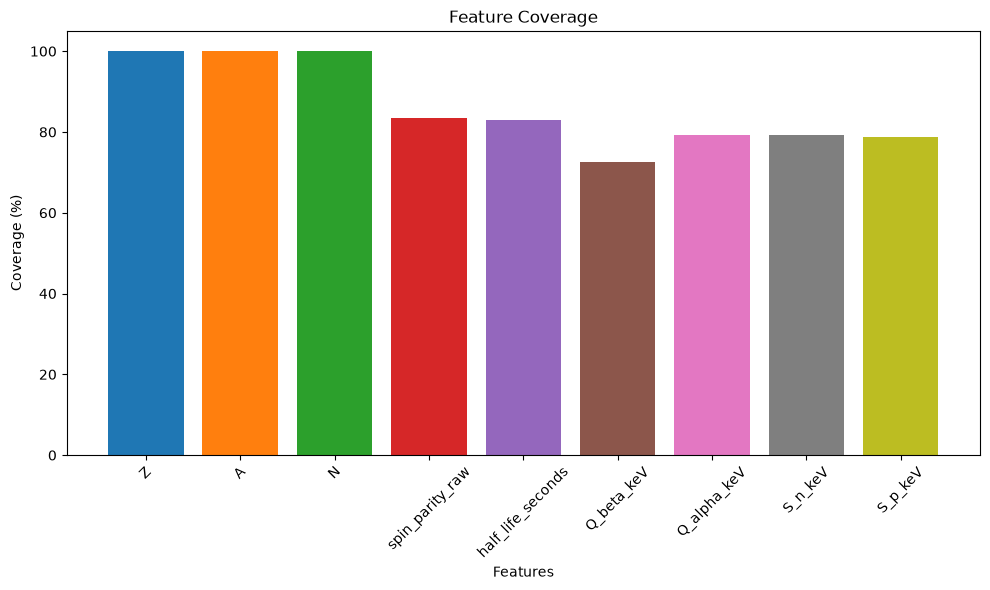

In [17]:
# Check feature coverage.

features = [
    "Z",
    "A",
    "N",
    "spin_parity_raw",
    "half_life_seconds",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV",
]

print("Feature coverage")
print("-" * 45)

for feature in features:
    available = sum(
        df[feature].notnull() & (df[feature] != "")
    )

    total = len(df)
    percentage = 100 * available / total if total else 0

    print(
        f"{feature:25s} "
        f"{available:6d}/{total:<6d} "
        f"({percentage:.1f}%)"
    )

# Create a bar chart to visualize the coverage of each feature
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for feature in features:
    available = sum(
        df[feature].notnull() & (df[feature] != "")
    )

    total = len(df)
    percentage = 100 * available / total if total else 0

    plt.bar(feature, percentage)
plt.xlabel("Features")
plt.ylabel("Coverage (%)")
plt.title("Feature Coverage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


half_life_status
finite          2796
stable           243
missing          215
unknown_unit     115
review             2
Name: count, dtype: int64


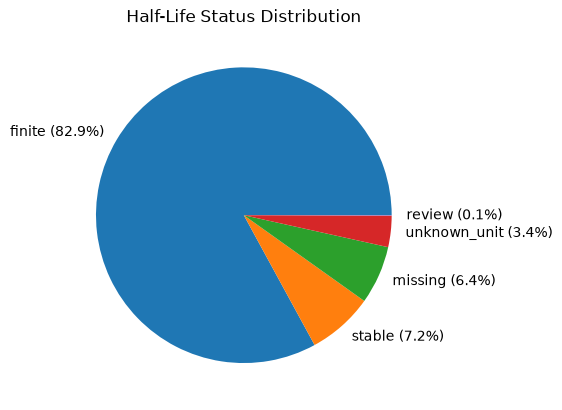

In [32]:
print(
    df["half_life_status"]
    .value_counts(dropna=False)
)

# Make pie chart of half-life status distribution with percentages included with labels 
import matplotlib.pyplot as plt

df["half_life_status"].value_counts(dropna=False).plot(kind="pie", labels=df["half_life_status"].value_counts(dropna=False).index + " (" + df["half_life_status"].value_counts(dropna=False).apply(lambda x: f"{x/len(df)*100:.1f}%") + ")")
plt.title("Half-Life Status Distribution")
plt.ylabel("")
plt.show()

         Q_beta_keV   Q_alpha_keV       S_n_keV       S_p_keV
count   2448.000000   2669.000000   2668.000000   2655.000000
mean     496.294888  -1201.801867   7545.141574   7244.687154
std     7475.566068   7373.073069   3636.438988   5397.433252
min   -24190.000000 -98404.000000 -10026.000000 -14690.000000
25%    -4277.357500  -6172.000000   5297.375000   3310.000000
50%       85.150000   -855.000000   7043.250000   6470.000000
75%     4999.175000   4599.000000   9277.657500  10287.000000
max    29530.000000  56298.000000  23970.000000  28540.000000


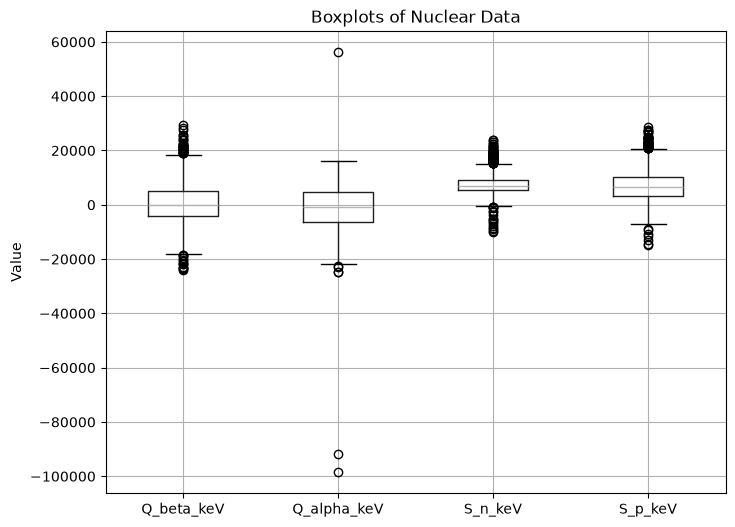

In [40]:
#Create a summary of the Q and S values to understand their distributions
print(df[["Q_beta_keV", "Q_alpha_keV", "S_n_keV", "S_p_keV"]].describe())

# Create a boxplot for each of the Q and S values to visualize their distributions  
plt.figure(figsize=(8, 6))
df.boxplot(column=["Q_beta_keV", "Q_alpha_keV", "S_n_keV", "S_p_keV"])
plt.title("Boxplots of Nuclear Data")
plt.ylabel("Value")
plt.show()

<Figure size 1200x800 with 0 Axes>

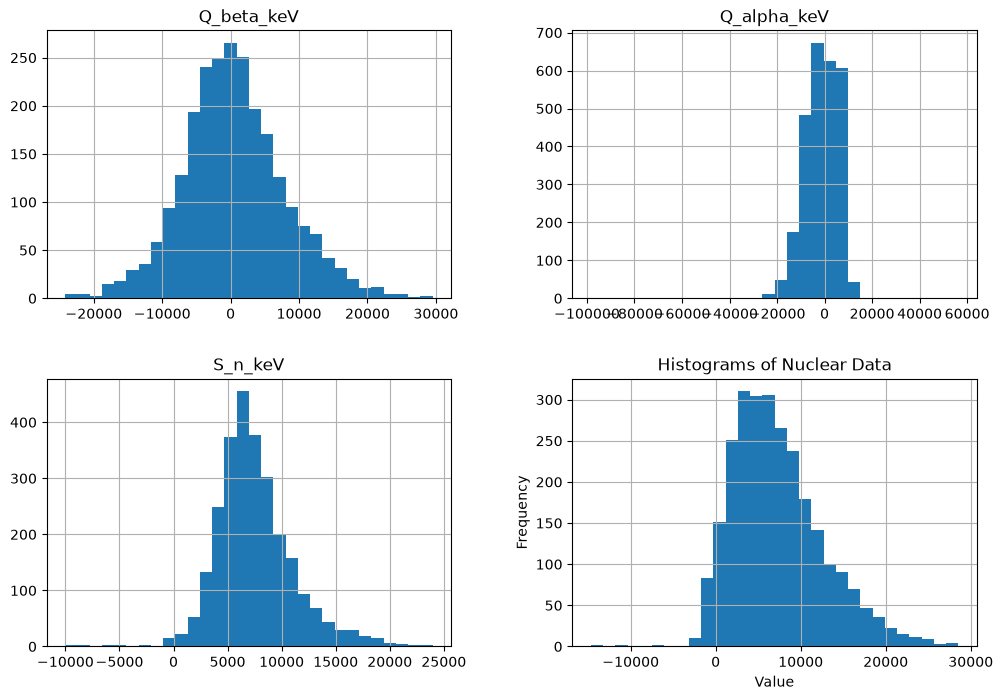

In [42]:
# Plot histograms for Q and S values to visualize their distributions
plt.figure(figsize=(12, 8))
df[["Q_beta_keV", "Q_alpha_keV", "S_n_keV", "S_p_keV"]].hist(bins=30, figsize=(12, 8))
plt.title("Histograms of Nuclear Data")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

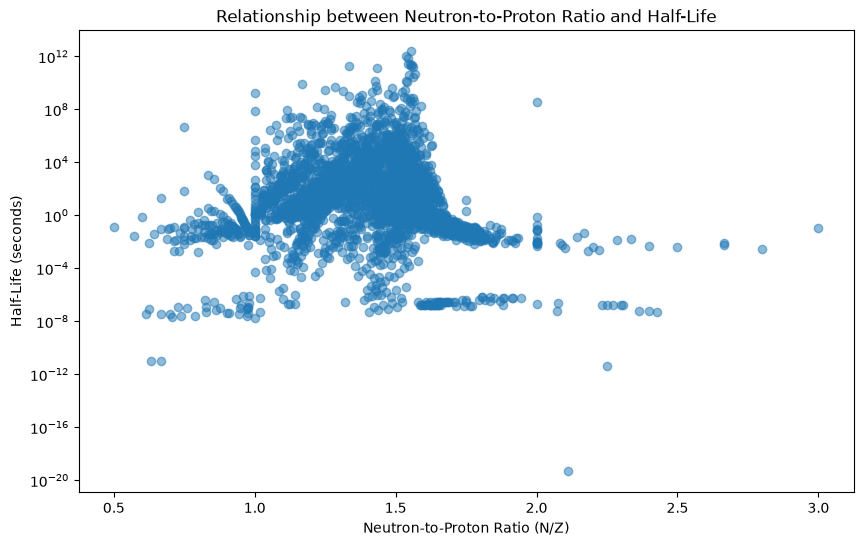

In [54]:
# Plot neutron-to-proton ratio (N/Z) vs. half-life (in seconds) to visualize the relationship between mass number and half-life
plt.figure(figsize=(10, 6))
plt.scatter(df[df["Z"] > 0]["N"] / df[df["Z"] > 0]["Z"], (df[df["Z"] > 0]["half_life_seconds"]), alpha=0.5)
plt.xlabel("Neutron-to-Proton Ratio (N/Z)")
plt.ylabel("Half-Life (seconds)")
plt.yscale("log")
plt.title("Relationship between Neutron-to-Proton Ratio and Half-Life")
plt.show()